# 03 · Fase B — Intervención preliminar: número de object queries
**Antes de ejecutar:** las hipótesis H1–H3 deben estar escritas y commiteadas en `DESIGN_LOG.md` (la celda siguiente imprime el commit como evidencia).
Una hipótesis, un cambio (N), una medición. Mismo protocolo, inicialización de queries (D6), resolución y semilla en todas las corridas.

In [1]:
import os, sys, subprocess
import warnings; warnings.filterwarnings('ignore', message=r'.*copying from a non-meta parameter')
REPO_URL = 'https://github.com/OscarLauLu/DETR-1INF52.git'
BRANCH   = 'rodrigo_dev'               # main aún no tiene el avance
REPO_DIR = 'DETR-1INF52'
if not os.path.exists('../src/common.py'):
    if not os.path.exists(f'{REPO_DIR}/src'):
        !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
    os.chdir(f'{REPO_DIR}/notebooks')
    !pip -q install -r ../requirements.txt
sys.path.insert(0, '../src')
from common import *
import torch, json, pandas as pd, matplotlib.pyplot as plt
os.makedirs('../results', exist_ok=True); os.makedirs('../data', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'; SEED = 42; set_seed(SEED)
COMMIT = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print(DEVICE, '| commit', COMMIT); print(env_report('../results/entorno.txt'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
cuda | commit eef222d
python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
torch 2.11.0+cu128
torchvision 0.26.0+cu128
transformers 4.57.6
timm 1.0.29
pycocotools ?
scipy 1.16.3
numpy 2.1.3
GPU Tesla T4 | CUDA 12.8


In [2]:
# Evidencia: último commit del design log (debe ser ANTERIOR a las corridas de abajo)
!git -C .. log -1 --format='%h  %ci  %s' -- DESIGN_LOG.md

eb4e906  2026-10-27 23:52:56 -0500  Correccion y ajustes del notebook 2


In [3]:
# Rutas de la copia de Kaggle de VisDrone (ajusta tras revisar el árbol en 01)
ROOT = '/kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset'
TRAIN_IMG, TRAIN_LBL = f'{ROOT}/VisDrone2019-DET-train/images', f'{ROOT}/VisDrone2019-DET-train/labels'
VAL_IMG,   VAL_LBL   = f'{ROOT}/VisDrone2019-DET-val/images',   f'{ROOT}/VisDrone2019-DET-val/labels'

from transformers import DetrImageProcessor, DetrForObjectDetection
CKPT = 'facebook/detr-resnet-50'
processor = DetrImageProcessor.from_pretrained(CKPT, size={'shortest_edge': 512, 'longest_edge': 853})   # D4
TRAIN_JSON, VAL_JSON = '../data/train_sub.json', '../data/val_sub.json'
assert os.path.exists(TRAIN_JSON) and os.path.exists(VAL_JSON), \
    'Faltan los JSON: ejecutar el notebook 01 y commitearlos en la rama clonada'
EPOCHS, BS = 8, 2                                                   # D13
groups, (q1, q2) = density_groups(VAL_JSON); print({k: len(v) for k, v in groups.items()}, 'cortes:', q1, q2)
cnt = objects_per_image(VAL_JSON)
print(pd.DataFrame({g: {N: round(oracle_recall([cnt[i] for i in ids], N), 3) for N in (100, 300, 500)}
                    for g, ids in groups.items()}).rename_axis('techo N'))   # techo analítico por grupo

preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

{'low': 185, 'medium': 180, 'high': 183, 'gt100': 106} cortes: 48.0 82.66666666666663
         low  medium   high  gt100
techo N                           
100      1.0     1.0  0.806  0.714
300      1.0     1.0  0.998  0.998
500      1.0     1.0  1.000  1.000


In [4]:
# D18 · Precarga: el preprocesamiento es determinista (sin aumentación), así que se hace una sola vez
# para train y val y se reutiliza en todas las épocas, variantes y evaluaciones.
import time

def preprocess_all(img_dir, ann_json):
    ds = CocoDetrDataset(img_dir, ann_json, processor)        # mismo orden que make_loader/predict: por id
    dl = torch.utils.data.DataLoader(ds, batch_size=None, shuffle=False, num_workers=os.cpu_count())
    return [(pv.clone(), lab) for pv, lab in dl]               # clone: fuera de la memoria compartida

class _Cached(torch.utils.data.Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def cached_loader(items, bs=BS, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)                 # mismo generador que make_loader -> mismo orden
    def collate(batch):
        enc = processor.pad([b[0] for b in batch], return_tensors='pt')
        return {'pixel_values': enc['pixel_values'], 'pixel_mask': enc['pixel_mask'],
                'labels': [b[1] for b in batch]}
    return torch.utils.data.DataLoader(_Cached(items), batch_size=bs, shuffle=True,
                                       collate_fn=collate, num_workers=0, generator=g)

def predict_cached(model, items, label_offset=1, label_map=None, bs=4):
    """Igual que predict(): mismos lotes de 4 y mismo relleno, sin volver a leer las imágenes."""
    imgs = sorted(json.load(open(VAL_JSON))['images'], key=lambda x: x['id'])
    model.to(DEVICE).eval(); dets = []
    for s in range(0, len(imgs), bs):
        chunk = imgs[s:s + bs]
        enc = processor.pad([items[i][0] for i in range(s, s + len(chunk))], return_tensors='pt')
        with torch.no_grad():
            out = model(pixel_values=enc['pixel_values'].to(DEVICE), pixel_mask=enc['pixel_mask'].to(DEVICE))
        sizes = torch.tensor([[im['height'], im['width']] for im in chunk])
        for im, r in zip(chunk, processor.post_process_object_detection(out, threshold=0.0, target_sizes=sizes)):
            for sc, lb, bx in zip(r['scores'].tolist(), r['labels'].tolist(), r['boxes'].tolist()):
                cid = lb + label_offset
                if label_map is not None:
                    if cid not in label_map: continue
                    cid = label_map[cid]
                dets.append({'image_id': im['id'], 'category_id': int(cid), 'score': float(sc),
                             'bbox': [bx[0], bx[1], bx[2] - bx[0], bx[3] - bx[1]]})
    return dets

def eval_groups(dets, cat_ids=None):
    res = {'overall': coco_eval(VAL_JSON, dets, cat_ids=cat_ids)}
    for g, ids in groups.items():
        res[g] = coco_eval(VAL_JSON, dets, img_ids=ids, cat_ids=cat_ids)
    return res

t = time.time()
TRAIN_CACHE = preprocess_all(TRAIN_IMG, TRAIN_JSON)
VAL_CACHE = preprocess_all(VAL_IMG, VAL_JSON)
gib = sum(pv.numel() * 4 for pv, _ in TRAIN_CACHE + VAL_CACHE) / 2**30
print(f'{len(TRAIN_CACHE)} train + {len(VAL_CACHE)} val preprocesadas en {time.time() - t:.0f} s | {gib:.1f} GiB en RAM')
!free -g | head -2

600 train + 548 val preprocesadas en 31 s | 5.0 GiB en RAM
               total        used        free      shared  buff/cache   available
Mem:              31           7          17           0           6          23


In [5]:
print(torch.__version__, torch.version.cuda, torch.cuda.get_device_name(0), torch.cuda.get_device_capability(0))
x = torch.randn(2, 3, 64, 64, device='cuda')
print(torch.nn.functional.relu(torch.nn.Conv2d(3, 8, 3).cuda()(x)).sum().item())

2.11.0+cu128 12.8 Tesla T4 (7, 5)
14460.896484375


## B0 · Punto de partida: DETR de COCO sin fine-tuning (zero-shot, N = 100)
Solo las 6 clases con equivalente en COCO (`COCO_TO_VISDRONE`). Es también la primera medición de la Fase C.

In [6]:
MAPPED = sorted(set(COCO_TO_VISDRONE.values()))
zs_model = DetrForObjectDetection.from_pretrained(CKPT)
zs_dets = predict_cached(zs_model, VAL_CACHE, label_offset=0, label_map=COCO_TO_VISDRONE)
zs = eval_groups(zs_dets, cat_ids=MAPPED)
del zs_model; torch.cuda.empty_cache()
print(pd.DataFrame(zs).T[['AP', 'AP50', 'AP_S', 'AR@100', 'AR@500', 'n_img']].round(3))
json.dump(zs, open('../results/zero_shot.json', 'w'), indent=1)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


            AP   AP50   AP_S  AR@100  AR@500  n_img
overall  0.061  0.116  0.010   0.107   0.107  548.0
low      0.087  0.174  0.018   0.157   0.157  185.0
medium   0.059  0.115  0.013   0.111   0.111  180.0
high     0.053  0.099  0.008   0.087   0.087  183.0
gt100    0.046  0.087  0.007   0.075   0.075  106.0


## B1 · Ablación (se reanuda si la sesión se cae: salta las N ya hechas)

In [7]:
import time
VARIANTS = (100, 300)                # añade 500 si hay tiempo (mismo protocolo)
RES_PATH = '../results/ablation_queries.json'
results = {int(k): v for k, v in json.load(open(RES_PATH)).items()} if os.path.exists(RES_PATH) else {}
for N in VARIANTS:
    if N in results: print('ya hecho', N); continue
    set_seed(SEED)
    model = build_model(num_queries=N, num_labels=10, freeze_backbone=True)       # D5, D6
    print(f'N={N}: parámetros {count_params(model)/1e6:.2f} M | entrenables {count_params(model, True)/1e6:.2f} M')
    tl = cached_loader(TRAIN_CACHE)
    t0 = time.time()
    hist = train(model, tl, EPOCHS, device=DEVICE, ckpt_path=f'/tmp/detr_N{N}.pt')   # checkpoint fuera del repo
    dets = predict_cached(model, VAL_CACHE); res = eval_groups(dets)
    res['mapped6'] = coco_eval(VAL_JSON, dets, cat_ids=MAPPED)                      # comparable con el zero-shot
    json.dump(dets, open(f'../results/dets_N{N}.json', 'w'))
    results[N] = {'loss': hist, 'eval': res, 'minutos': round((time.time() - t0) / 60, 1)}
    json.dump(results, open(RES_PATH, 'w'), indent=1)
    print(N, {k: round(v, 3) for k, v in res['overall'].items()}); del model; torch.cuda.empty_cache()

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DetrForObjectDetection were not initialized from the model checkpoin

N=100: parámetros 41.50 M | entrenables 18.05 M


/kaggle/working/DETR-1INF52/notebooks/../src/common.py:291: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  comps[k] = comps.get(k, 0.0) + float(v)


  ep 1 it 0/300 loss 3.932
  ep 1 it 100/300 loss 2.957
  ep 1 it 200/300 loss 4.021
época 1/8: loss 3.9432 (38.6 s)
  ep 2 it 0/300 loss 3.032
  ep 2 it 100/300 loss 4.002
  ep 2 it 200/300 loss 2.755
época 2/8: loss 3.6911 (40.0 s)
  ep 3 it 0/300 loss 2.632
  ep 3 it 100/300 loss 3.489
  ep 3 it 200/300 loss 3.010
época 3/8: loss 3.6331 (39.6 s)
  ep 4 it 0/300 loss 2.403
  ep 4 it 100/300 loss 3.349
  ep 4 it 200/300 loss 2.213
época 4/8: loss 3.6105 (39.6 s)
  ep 5 it 0/300 loss 3.891
  ep 5 it 100/300 loss 3.428
  ep 5 it 200/300 loss 2.858
época 5/8: loss 3.5432 (39.6 s)
  ep 6 it 0/300 loss 3.160
  ep 6 it 100/300 loss 3.401
  ep 6 it 200/300 loss 3.796
época 6/8: loss 3.4608 (39.4 s)
  ep 7 it 0/300 loss 3.400
  ep 7 it 100/300 loss 3.676
  ep 7 it 200/300 loss 2.967
época 7/8: loss 3.4904 (39.6 s)
  ep 8 it 0/300 loss 3.429
  ep 8 it 100/300 loss 3.155
  ep 8 it 200/300 loss 3.538
época 8/8: loss 3.4816 (39.6 s)
100 {'AP': 0.009, 'AP50': 0.026, 'AP75': 0.007, 'AP_S': 0.001, '

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DetrForObjectDetection were not initialized from the model checkpoin

N=300: parámetros 41.56 M | entrenables 18.10 M
  ep 1 it 0/300 loss 3.455
  ep 1 it 100/300 loss 4.729
  ep 1 it 200/300 loss 3.719
época 1/8: loss 3.6265 (43.2 s)
  ep 2 it 0/300 loss 3.793
  ep 2 it 100/300 loss 3.057
  ep 2 it 200/300 loss 3.829
época 2/8: loss 3.3710 (41.7 s)
  ep 3 it 0/300 loss 4.127
  ep 3 it 100/300 loss 2.676
  ep 3 it 200/300 loss 2.810
época 3/8: loss 3.3191 (42.2 s)
  ep 4 it 0/300 loss 1.871
  ep 4 it 100/300 loss 2.889
  ep 4 it 200/300 loss 1.774
época 4/8: loss 3.3525 (41.9 s)
  ep 5 it 0/300 loss 4.224
  ep 5 it 100/300 loss 3.815
  ep 5 it 200/300 loss 2.825
época 5/8: loss 3.3274 (41.9 s)
  ep 6 it 0/300 loss 2.891
  ep 6 it 100/300 loss 2.731
  ep 6 it 200/300 loss 3.393
época 6/8: loss 3.3142 (41.8 s)
  ep 7 it 0/300 loss 2.946
  ep 7 it 100/300 loss 3.314
  ep 7 it 200/300 loss 2.704
época 7/8: loss 3.2801 (42.1 s)
  ep 8 it 0/300 loss 3.053
  ep 8 it 100/300 loss 2.733
  ep 8 it 200/300 loss 3.288
época 8/8: loss 3.2727 (41.9 s)
300 {'AP': 0.005

      N    grupo     AP   AP50   AP_S  AR@100  AR@500  n_img
0   100  overall  0.009  0.026  0.001   0.024   0.024    548
1   100      low  0.023  0.057  0.002   0.057   0.057    185
2   100   medium  0.009  0.027  0.002   0.025   0.025    180
3   100     high  0.005  0.015  0.001   0.013   0.013    183
4   100    gt100  0.004  0.013  0.001   0.011   0.011    106
5   100  mapped6  0.015  0.042  0.001   0.039   0.039    548
6   300  overall  0.005  0.012  0.001   0.021   0.023    548
7   300      low  0.011  0.027  0.001   0.046   0.049    185
8   300   medium  0.005  0.014  0.000   0.023   0.025    180
9   300     high  0.003  0.008  0.001   0.011   0.013    183
10  300    gt100  0.002  0.007  0.000   0.010   0.011    106
11  300  mapped6  0.008  0.021  0.001   0.034   0.037    548


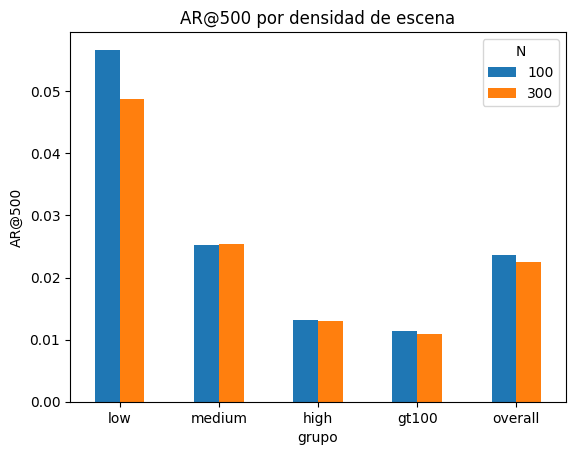

In [8]:
rows = [{'N': N, 'grupo': g, **m} for N, r in results.items() for g, m in r['eval'].items()]
T = pd.DataFrame(rows); print(T[['N', 'grupo', 'AP', 'AP50', 'AP_S', 'AR@100', 'AR@500', 'n_img']].round(3).to_string())
T.to_csv('../results/ablation_queries.csv', index=False)
order = [g for g in ['low', 'medium', 'high', 'gt100', 'overall'] if g in set(T['grupo'])]
P = T.pivot(index='grupo', columns='N', values='AR@500').loc[order]
P.plot(kind='bar'); plt.ylabel('AR@500'); plt.title('AR@500 por densidad de escena'); plt.xticks(rotation=0)
plt.savefig('../results/ar500_por_densidad.png', dpi=150, bbox_inches='tight')

## B2 · Recall por imagen vs techo analítico min(1, N/n) (H1)
IoU ≥ 0.5, emparejamiento 1 a 1 por clase. Si los puntos de N=100 se pegan a la curva para n > 100, el techo está activo; si quedan muy por debajo, otro factor actúa antes (resolución, objetos pequeños, shift).

N=100
                    n  recall  imgs
bin                               
(0, 25]       13.357   0.474    84
(25, 50]      39.282   0.268   110
(50, 100]     74.359   0.170   248
(100, 150]   118.145   0.117    76
(150, 200]   173.818   0.068    22
(200, 300]   222.200   0.060     5
(300, 1000]  311.333   0.028     3
N=300
                    n  recall  imgs
bin                               
(0, 25]       13.357   0.473    84
(25, 50]      39.282   0.273   110
(50, 100]     74.359   0.176   248
(100, 150]   118.145   0.121    76
(150, 200]   173.818   0.067    22
(200, 300]   222.200   0.062     5
(300, 1000]  311.333   0.027     3


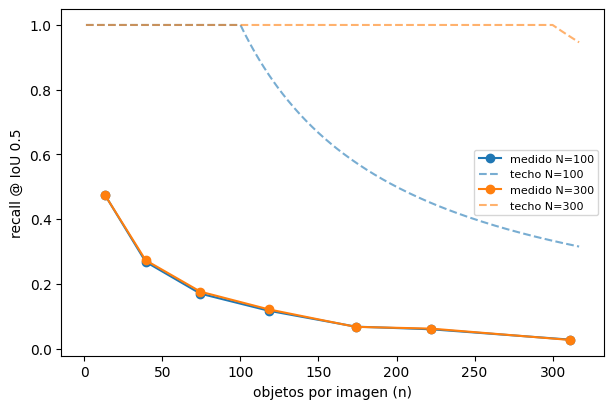

In [9]:
import numpy as np
fig, ax = plt.subplots(figsize=(7, 4.5)); xs = np.arange(1, max(cnt.values()) + 1)
for N in sorted(results):
    R = pd.DataFrame(per_image_recall(VAL_JSON, json.load(open(f'../results/dets_N{N}.json')))).dropna()
    R['bin'] = pd.cut(R['n_gt'], bins=[0, 25, 50, 100, 150, 200, 300, 1000])
    B = R.groupby('bin', observed=True).agg(n=('n_gt', 'mean'), recall=('recall', 'mean'), imgs=('recall', 'size'))
    print(f'N={N}\n', B.round(3)); B.to_csv(f'../results/recall_por_densidad_N{N}.csv')
    l, = ax.plot(B['n'], B['recall'], 'o-', label=f'medido N={N}')
    ax.plot(xs, np.minimum(1, N / xs), '--', color=l.get_color(), alpha=.6, label=f'techo N={N}')
ax.set_xlabel('objetos por imagen (n)'); ax.set_ylabel('recall @ IoU 0.5'); ax.legend(fontsize=8)
plt.savefig('../results/recall_vs_techo.png', dpi=150, bbox_inches='tight')

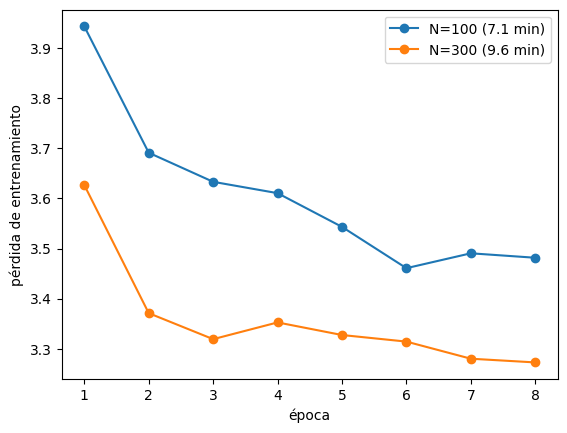

In [10]:
for N, r in sorted(results.items()):
    plt.plot([h['epoch'] for h in r['loss']], [h['loss'] for h in r['loss']], 'o-', label=f'N={N} ({r["minutos"]} min)')
plt.xlabel('época'); plt.ylabel('pérdida de entrenamiento'); plt.legend(); plt.savefig('../results/curvas_perdida.png', dpi=150, bbox_inches='tight')

## Contraste con las hipótesis (completar en el design log)
- **H1** (recall cae con N=100 en escenas densas): mirar `gt100`/`high` vs `low` y la figura recall vs techo. ¿Se cumplió? ¿por qué?
- **H2** (más queries ayuda sobre todo en escenas densas): diferencia N=300 − N=100 por grupo. ¿Es mayor en `high` que en `low`? ¿La pérdida converge peor con más queries?
- **H3** (costo bajo): tabla `costo_vs_N.csv` del notebook 02 (A8).

⚠️ Entrenamiento corto (8 épocas) en un subconjunto de 600 imágenes: interpreten **diferencias relativas**, no el AP absoluto. Repórtenlo como limitación.